In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, SystemMessage, BaseMessage
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver


In [2]:
load_dotenv()

True

In [3]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [4]:
class ChatState(TypedDict):
    
    messages: Annotated[list[BaseMessage], add_messages]

In [5]:
checkpointer = MemorySaver()
graph = StateGraph(ChatState)

In [6]:
def chat_node(state: ChatState):
    
    messages = [SystemMessage(content="You are an helpful assistant")] + state['messages']
    response = model.invoke(messages)


    return {
        "messages" : [response]
    }

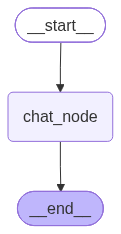

In [7]:
graph.add_node("chat_node", chat_node)

graph.add_edge(START, "chat_node")
graph.add_edge("chat_node", END)

workflow = graph.compile(checkpointer=checkpointer)
workflow

In [10]:
thread_id = '1'
while True:
    
    user_input = input("Type here:")
    print("You: ",user_input)
    
    if user_input.strip().lower() in ["exit", "quit", "bye"]:
        break
    
    config = {"configurable" : {'thread_id': thread_id}}    
    response = workflow.invoke({"messages": [HumanMessage(content=user_input)]}, config=config)
    print("AI:", response['messages'][-1].content)

You:  Hello
AI: Hi there! How can I help you today?
You:  What is the persistence in langgraph ?
AI: ### Persistence in LangGraph – What It Is and Why It Matters

> **TL;DR**  
> *Persistence* in LangGraph is the mechanism that lets a graph “remember” its state (nodes, edges, memory, context, etc.) between runs.  
> It is optional, but indispensable for any real‑world application that needs to keep track of conversations, long‑running workflows, or shared state across multiple workers.

---

## 1. Why Persistence Exists

| Problem | Why you need persistence |
|---------|--------------------------|
| **Multi‑turn conversations** | The graph must keep the user’s chat history, last intent, or context across turns. |
| **Long‑running workflows** | A job that may pause, crash, or run on different machines must be able to resume from where it left off. |
| **Distributed execution** | Multiple workers or services may need to access the same graph state (e.g., in a micro‑services architecture)

In [9]:
workflow.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='HEllo', additional_kwargs={}, response_metadata={}, id='5a8d8f7e-5ea6-493f-9d9e-a514e6b93552'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "HEllo". They likely want a greeting reply. The developer says "You are an helpful assistant". So respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 47, 'prompt_tokens': 81, 'total_tokens': 128, 'completion_time': 0.059507504, 'completion_tokens_details': {'reasoning_tokens': 29}, 'prompt_time': 0.007221832, 'prompt_tokens_details': None, 'queue_time': 0.356293399, 'total_time': 0.066729336}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a4315eb300', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a15f79-fede-7662-82fa-b4aeba108e84-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 81, 'output_tokens'